# Decision Trees and Random Forests

Previously we have looked in depth at a simple generative classifier (naive Bayes; see [Naive Bayes Classification](Naive-Bayes.ipynb)) and a powerful discriminative classifier (support vector machines; see [ Support Vector Machines](https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html)).
Here we'll take a look at another powerful algorithm: a nonparametric algorithm called *random forests*.
Random forests are an example of an *ensemble* method, meaning one that relies on aggregating the results of a set of simpler estimators.
The somewhat surprising result with such ensemble methods is that the sum can be greater than the parts: that is, the predictive accuracy of a majority vote among a number of estimators can end up being better than that of any of the individual estimators doing the voting!
We will see examples of this in the following sections.

We begin with the standard imports:

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

## Motivating Random Forests: Decision Trees

Random forests are an example of an ensemble learner built on decision trees.
For this reason, we'll start by discussing decision trees themselves.

Decision trees are extremely intuitive ways to classify or label objects: you simply ask a series of questions designed to zero in on the classification.
For example, if you wanted to build a decision tree to classify animals you come across while on a hike, you might construct the one shown in the following figure.

![](img/05.08-decision-tree.png)
[figure source in Appendix](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/06.00-Figure-Code.ipynb#Decision-Tree-Example)

The binary splitting makes this extremely efficient: in a well-constructed tree, each question will cut the number of options by approximately half, very quickly narrowing the options even among a large number of classes.
The trick, of course, comes in deciding which questions to ask at each step.
In machine learning implementations of decision trees, the questions generally take the form of axis-aligned splits in the data: that is, each node in the tree splits the data into two groups using a cutoff value within one of the features.
Let's now look at an example of this.

### Creating a Decision Tree

Consider the following two-dimensional data, which has one of four class labels (see the following figure):

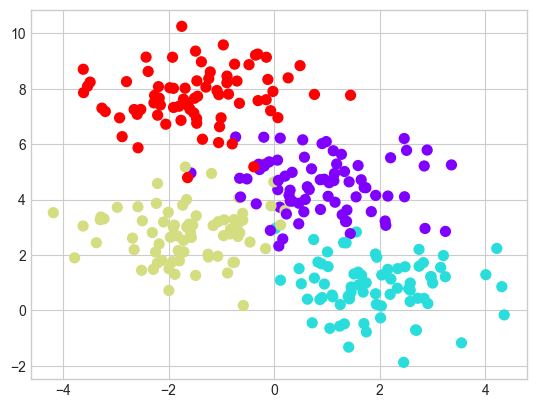

In [3]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=300, centers=4,
                  random_state=0, cluster_std=1.0)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='rainbow');

A simple decision tree built on this data will iteratively split the data along one or the other axis according to some quantitative criterion, and at each level assign the label of the new region according to a majority vote of points within it.
The following figure presents a visualization of the first four levels of a decision tree classifier for this data.

![](img/05.08-decision-tree-levels.png)
[figure source in Appendix](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/06.00-Figure-Code.ipynb#Decision-Tree-Levels)

Notice that after the first split, every point in the upper branch remains unchanged, so there is no need to further subdivide this branch.
Except for nodes that contain all of one color, at each level *every* region is again split along one of the two features.

This process of fitting a decision tree to our data can be done in Scikit-Learn with the ``DecisionTreeClassifier`` estimator:

In [4]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier().fit(X, y)

Let's write a utility function to help us visualize the output of the classifier:

In [5]:
def visualize_classifier(model, X, y, ax=None, cmap='rainbow'):
    ax = ax or plt.gca()
    
    # Plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=cmap,
               clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # fit the estimator
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200),
                         np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Create a color plot with the results
    n_classes = len(np.unique(y))
    contours = ax.contourf(xx, yy, Z, alpha=0.3,
                           levels=np.arange(n_classes + 1) - 0.5,
                           cmap=cmap, zorder=1)

    ax.set(xlim=xlim, ylim=ylim)

Now we can examine what the decision tree classification looks like (see the following figure):

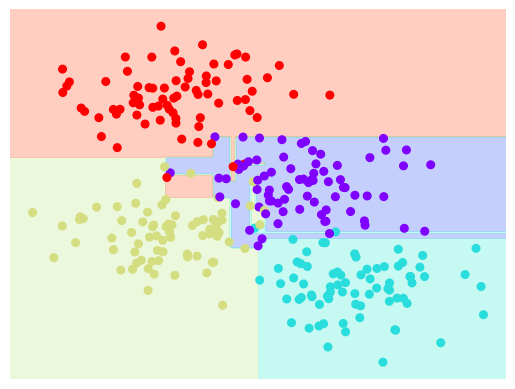

In [6]:
visualize_classifier(DecisionTreeClassifier(), X, y)

If you're running this notebook live, you can use the helper script included in the online [appendix](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/06.00-Figure-Code.ipynb#Helper-Code) to bring up an interactive visualization of the decision tree building process:

In [7]:
# Optional interactive visualization from the original online appendix.
# This helper module is not bundled with the notebook, so the cell is disabled by default.
# To use it, download helpers_05_08.py from the linked appendix and uncomment:
# import helpers_05_08
# helpers_05_08.plot_tree_interactive(X, y)

Notice that as the depth increases, we tend to get very strangely shaped classification regions; for example, at a depth of five, there is a tall and skinny purple region between the yellow and blue regions.
It's clear that this is less a result of the true, intrinsic data distribution, and more a result of the particular sampling or noise properties of the data.
That is, this decision tree, even at only five levels deep, is clearly overfitting our data.

### Decision Trees and Overfitting

Such overfitting turns out to be a general property of decision trees: it is very easy to go too deep in the tree, and thus to fit details of the particular data rather than the overall properties of the distributions it is drawn from.
Another way to see this overfitting is to look at models trained on different subsets of the data—for example, in this figure we train two different trees, each on half of the original data.

![](img/05.08-decision-tree-overfitting.png)
[figure source in Appendix](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/06.00-Figure-Code.ipynb#Decision-Tree-Overfitting)

It is clear that in some places the two trees produce consistent results (e.g., in the four corners), while in other places the two trees give very different classifications (e.g., in the regions between any two clusters).
The key observation is that the inconsistencies tend to happen where the classification is less certain, and thus by using information from *both* of these trees, we might come up with a better result!

If you are running this notebook live, the following function will allow you to interactively display the fits of trees trained on a random subset of the data:

In [8]:
# Optional interactive visualization from the original online appendix.
# This helper module is not bundled with the notebook, so the cell is disabled by default.
# To use it, download helpers_05_08.py from the linked appendix and uncomment:
# import helpers_05_08
# helpers_05_08.randomized_tree_interactive(X, y)

## Decision Tree Construction: The Hunt Algorithm

A decision tree is grown recursively. Let $D_t$ denote the training examples that reach node $t$. The Hunt algorithm is a general recursive template for this process:

1. **Pure node:** If all examples in $D_t$ belong to the same class, make $t$ a leaf and assign that class.
2. **Stopping condition:** If a stopping rule is met (for example, maximum depth, too few samples, or no useful split), make $t$ a leaf and assign the majority class.
3. **Select a split:** Otherwise, choose the feature test and threshold that produce the largest reduction in impurity.
4. **Recurse:** Partition $D_t$ among the child nodes and apply the same procedure to each child.

For a binary split on feature $x_j$ at threshold $s$,

$$
D_L=\{(x,y)\in D_t:x_j\leq s\},\qquad
D_R=\{(x,y)\in D_t:x_j>s\}.
$$

**Greedy construction.** The split is selected locally at the current node. The algorithm does not search all possible complete trees, so a locally optimal split is not guaranteed to be part of a globally optimal tree. This greedy strategy makes tree construction practical.

```text
HUNT(D_t):
    if D_t is empty:
        return a default leaf
    if all labels in D_t are identical:
        return a leaf with that label
    if a stopping condition is satisfied:
        return a majority-class leaf

    s* = the candidate split with the greatest impurity reduction
    D_left, D_right = partition D_t using s*
    return node(s*, HUNT(D_left), HUNT(D_right))
```

## Node Impurity and Split Criteria

Suppose node $t$ contains $K$ classes and the proportion of class $k$ is $p_k$.

### Entropy

$$
H(t)=-\sum_{k=1}^{K}p_k\log_2(p_k),
$$

where $0\log_2 0$ is defined as zero. Entropy is zero for a pure node and is largest when the classes are equally represented. For a binary node its maximum is one bit.

### Gini impurity

$$
G(t)=1-\sum_{k=1}^{K}p_k^2.
$$

Gini impurity is also zero for a pure node. It can be interpreted as the probability of misclassification if a class label is randomly assigned according to the class proportions in the node, independently of the example's true class.

### Classification error

$$
E(t)=1-\max_k p_k.
$$

This is the fraction of examples that would be misclassified if every example in the node were assigned the node's majority class.

### Information gain and weighted impurity reduction

For a candidate split $s$ with children $c$, the information gain is the reduction in weighted entropy:

$$
IG(s)=H(t)-\sum_{c}\frac{N_c}{N_t}H(c),
$$

where $N_t$ and $N_c$ are the number of examples in the parent and child nodes. The analogous Gini reduction is

$$
\Delta G(s)=G(t)-\sum_c\frac{N_c}{N_t}G(c).
$$

A split is preferred when it produces a large reduction. In terminology, **information gain** usually means entropy reduction; when Gini is used, call the quantity Gini reduction rather than information gain.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def node_impurities(y):
    """Return entropy (bits), Gini impurity, and classification error."""
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    entropy = -np.sum(p[p > 0] * np.log2(p[p > 0])) + 0.0   # + 0.0 avoids printing -0.0 for pure nodes
    gini = 1.0 - np.sum(p ** 2)
    classification_error = 1.0 - np.max(p)
    return entropy, gini, classification_error

# A node containing 6 examples of class A and 4 of class B
y_demo = np.array(["A"] * 6 + ["B"] * 4)
entropy, gini, class_error = node_impurities(y_demo)

print(f"Entropy: {entropy:.4f} bits")
print(f"Gini impurity: {gini:.4f}")
print(f"Classification error: {class_error:.4f}")

# Compare the criteria for several binary class distributions
distributions = {
    "Pure (10, 0)": [10, 0],
    "Imbalanced (9, 1)": [9, 1],
    "Moderate (7, 3)": [7, 3],
    "Balanced (5, 5)": [5, 5],
}
rows = []
for name, counts in distributions.items():
    labels = np.repeat([0, 1], counts)
    rows.append([name, *node_impurities(labels)])

pd.DataFrame(
    rows,
    columns=["Class counts", "Entropy", "Gini", "Classification error"]
).round(4)

Entropy: 0.9710 bits
Gini impurity: 0.4800
Classification error: 0.4000


,Class counts,Entropy,Gini,Classification error
0,"Pure (10, 0)",0.0000,0.00,0.0
1,"Imbalanced (9, 1)",0.4690,0.18,0.1
2,"Moderate (7, 3)",0.8813,0.42,0.3
3,"Balanced (5, 5)",1.0000,0.50,0.5


### Comparing the impurity criteria

- **Entropy and Gini** both measure class mixture and often rank candidate splits similarly. Gini is computationally simpler and is a common criterion in CART implementations.
- **Classification error** depends only on the majority-class proportion. It is less sensitive to changes in class probabilities that do not change the majority class, so it is usually less useful for growing a tree.
- **Entropy** has an information-theoretic interpretation and responds smoothly to changes in class proportions.
- No criterion is guaranteed to produce the best test performance on every dataset. The final model must be evaluated on data not used to fit it.

## Greedy Split Search and Computational Cost

For a continuous feature $x_j$, sort its values at the current node. Candidate thresholds are commonly placed halfway between adjacent distinct sorted values:

$$
s_i=\frac{x_{(i)}+x_{(i+1)}}{2}.
$$

For each feature and candidate threshold, the algorithm:
1. partitions the node's examples into left and right children;
2. computes the impurity of each child;
3. computes the child-size-weighted impurity;
4. selects the split with the largest impurity reduction.

$$
s^*=\arg\max_s\left[I(t)-\sum_c\frac{N_c}{N_t}I(c)\right].
$$

### Complexity (one node)

Let $n$ be the number of examples at the node, $d$ the number of features, and $K$ the number of classes. A straightforward implementation that sorts each continuous feature costs approximately $O(dn\log n)$. Once sorted, scanning candidate boundaries while maintaining cumulative class counts costs about $O(dnK)$. Thus a useful upper-level estimate for one node is

$$
O(dn\log n+dnK).
$$

The total training cost depends on how the examples are distributed across the resulting tree. A balanced tree and a highly unbalanced tree can have very different costs. Prediction for one observation follows one root-to-leaf path and takes approximately $O(h)$ comparisons, where $h$ is the tree depth.

**Implementation note:** Efficient libraries may reuse sorted feature orders, use histograms, or apply other optimizations, so this is an explanatory estimate rather than an exact runtime formula for every implementation.

In [10]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1.0 - np.sum(p ** 2)

def rank_1d_gini_splits(x, y):
    """Educational exhaustive threshold search for one continuous feature."""
    order = np.argsort(x)
    xs = np.asarray(x)[order]
    ys = np.asarray(y)[order]
    thresholds = (xs[:-1] + xs[1:]) / 2
    thresholds = thresholds[xs[:-1] != xs[1:]]
    parent_gini = gini_impurity(ys)

    results = []
    for threshold in thresholds:
        left, right = ys[xs <= threshold], ys[xs > threshold]
        weighted_child_gini = (
            len(left) / len(ys) * gini_impurity(left)
            + len(right) / len(ys) * gini_impurity(right)
        )
        results.append((threshold, weighted_child_gini,
                        parent_gini - weighted_child_gini))

    return pd.DataFrame(
        results,
        columns=["threshold", "weighted_child_gini", "gini_reduction"]
    ).sort_values("gini_reduction", ascending=False).reset_index(drop=True)

# Small example: inspect the candidate thresholds and their scores
x_small = np.array([1.0, 1.2, 1.8, 2.0, 3.2, 3.5, 4.0, 4.4])
y_small = np.array([0, 0, 0, 1, 1, 1, 1, 1])
rank_1d_gini_splits(x_small, y_small).round(4)

,threshold,weighted_child_gini,gini_reduction
0,1.90,0.0000,0.4688
1,2.60,0.1875,0.2812
2,1.50,0.2083,0.2604
3,3.35,0.3000,0.1688
4,1.10,0.3571,0.1116
5,3.75,0.3750,0.0938
6,4.20,0.4286,0.0402


## Numerical Experiment: A Decision Tree on the Iris Dataset

The Iris dataset contains 150 observations, three species, and four numeric features. We use a stratified hold-out split so that each species is represented proportionally in the training and test sets. The tree below is deliberately grown without a depth limit to inspect its structure.

The experiment reports more than accuracy: tree depth and number of leaves describe model complexity, while the classification report and confusion matrix help identify class-specific errors.

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris, y_iris, test_size=0.30, stratify=y_iris, random_state=42
)

iris_tree = DecisionTreeClassifier(criterion="gini", random_state=42)
iris_tree.fit(X_iris_train, y_iris_train)

train_pred = iris_tree.predict(X_iris_train)
test_pred = iris_tree.predict(X_iris_test)

print(f"Training accuracy: {accuracy_score(y_iris_train, train_pred):.4f}")
print(f"Test accuracy: {accuracy_score(y_iris_test, test_pred):.4f}")
print(f"Balanced test accuracy: {balanced_accuracy_score(y_iris_test, test_pred):.4f}")
print(f"Tree depth: {iris_tree.get_depth()}")
print(f"Number of leaves: {iris_tree.get_n_leaves()}")
print("\nTest-set classification report:")
print(classification_report(
    y_iris_test, test_pred, target_names=iris.target_names
))

Training accuracy: 1.0000
Test accuracy: 0.9333
Balanced test accuracy: 0.9333
Tree depth: 5
Number of leaves: 8

Test-set classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



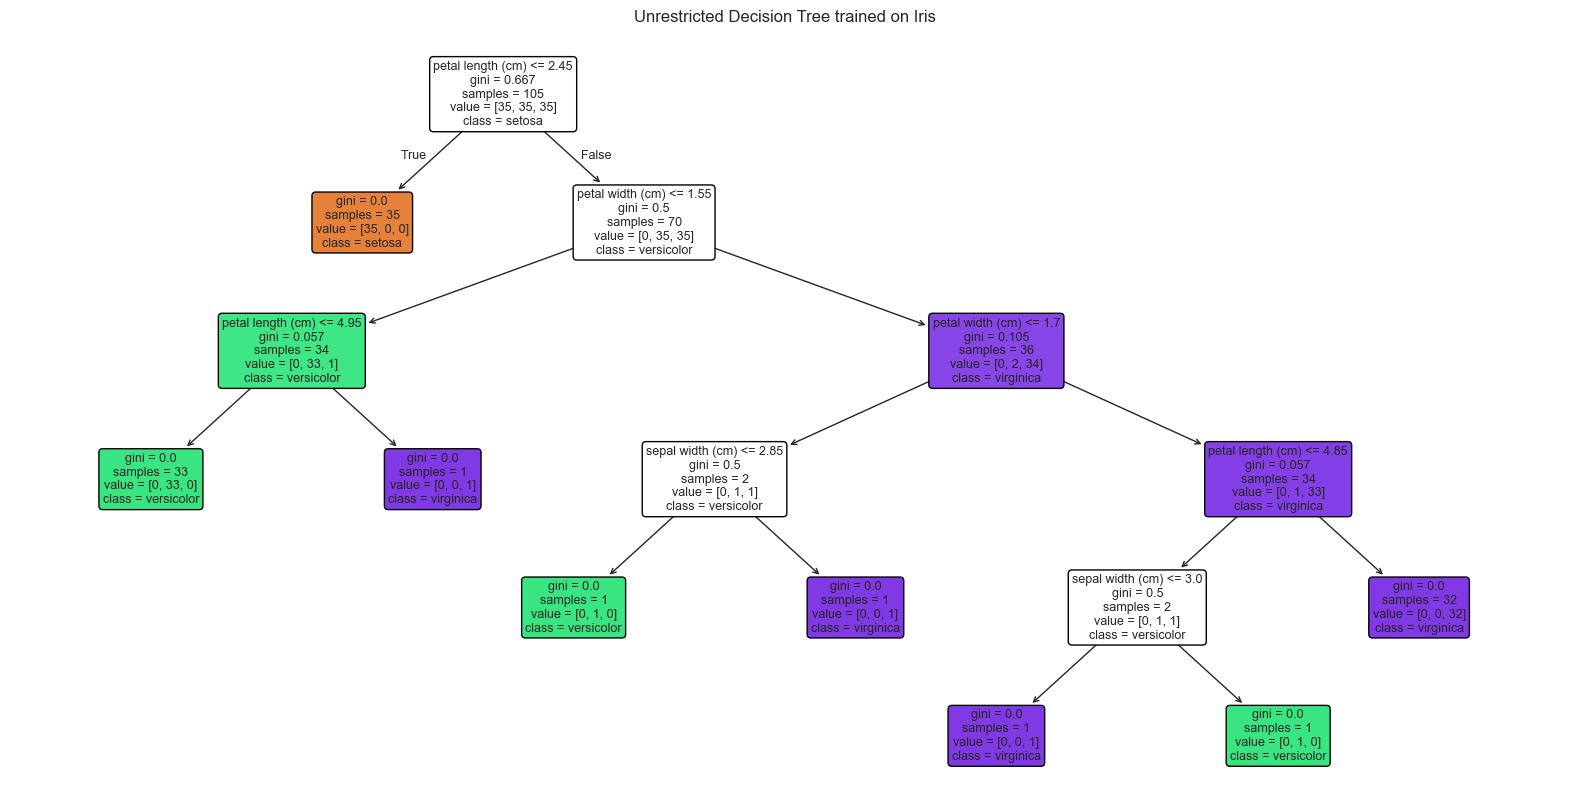

In [12]:
plt.figure(figsize=(20, 10))
plot_tree(
    iris_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=9
)
plt.title("Unrestricted Decision Tree trained on Iris")
plt.show()

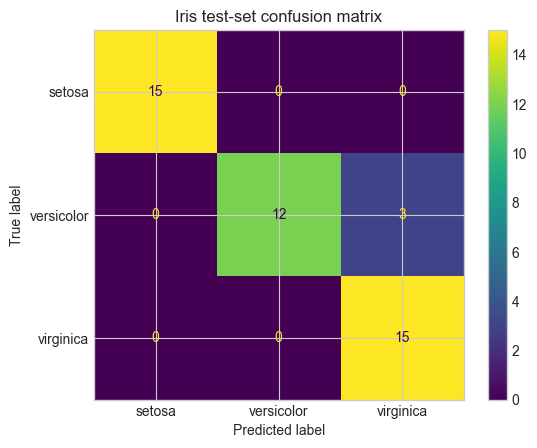

In [13]:
ConfusionMatrixDisplay.from_estimator(
    iris_tree, X_iris_test, y_iris_test,
    display_labels=iris.target_names, values_format="d"
)
plt.title("Iris test-set confusion matrix")
plt.show()

### How to Interpret the Iris Results

In this run (stratified 70/30 split, `random_state=42`):

- **Train vs. test accuracy:** 1.0000 on the training set and 0.9333 on the test set, a gap of 0.0667. The unrestricted tree fits the training data perfectly but generalizes slightly worse.
- **Complexity:** depth 5 and 8 leaves.
- **Root split:** `petal length (cm) <= 2.45`.
- **Errors:** 3 test sample(s) of true class *versicolor* were predicted as *virginica*. Setosa is perfectly separated; the errors are all between the two overlapping species, versicolor and virginica.

A tree that classifies its training examples perfectly is not automatically the best model. The goal is reliable performance on previously unseen observations. With only 45 test samples, one extra mistake changes the accuracy by about 2.2 percentage points, so this difference should not be over-interpreted.

## Controlled Overfitting Experiment: Noisy Training Labels

A fully grown tree can keep splitting until it isolates very small groups of observations. If some training labels are incorrect or noisy, a sufficiently deep tree may learn those accidental labels instead of the underlying pattern.

The experiment below creates a two-class nonlinear dataset. Each training label is flipped independently with probability 20% (the realized fraction in the run below is printed by the code), while the test labels are left unchanged. We then compare trees of different maximum depths. This makes it possible to distinguish fitting the noisy training labels from learning the underlying classification pattern.

In [14]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(
    n_samples=1600, noise=0.28, random_state=7
)
X_m_train, X_m_test, y_m_train_clean, y_m_test = train_test_split(
    X_moons, y_moons, test_size=0.30,
    stratify=y_moons, random_state=11
)

rng_noise = np.random.default_rng(123)
y_m_train_noisy = y_m_train_clean.copy()
flip_mask = rng_noise.random(len(y_m_train_noisy)) < 0.20
y_m_train_noisy[flip_mask] = 1 - y_m_train_noisy[flip_mask]

print(f"Fraction of flipped training labels: {flip_mask.mean():.3f}")

Fraction of flipped training labels: 0.180


In [15]:
depth_values = [1, 2, 3, 4, 5, 7, 10, 15, None]
overfit_rows = []
overfit_models = {}

for depth in depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_m_train, y_m_train_noisy)
    overfit_models[depth] = model
    overfit_rows.append({
        "max_depth": "None" if depth is None else depth,
        "train_acc_noisy": accuracy_score(
            y_m_train_noisy, model.predict(X_m_train)
        ),
        "test_acc_clean": accuracy_score(
            y_m_test, model.predict(X_m_test)
        ),
        "actual_depth": model.get_depth(),
        "n_leaves": model.get_n_leaves()
    })

overfit_results = pd.DataFrame(overfit_rows)
overfit_results.round(4)

,max_depth,train_acc_noisy,test_acc_clean,actual_depth,n_leaves
0,1,0.7089,0.7958,1,2
1,2,0.7625,0.8833,2,4
2,3,0.7625,0.8833,3,8
3,4,0.7670,0.8729,4,15
4,5,0.7705,0.8708,5,27
5,7,0.8179,0.8688,7,65
6,10,0.8857,0.8354,10,151
7,15,0.9670,0.7521,15,267
8,None,1.0000,0.7250,27,313


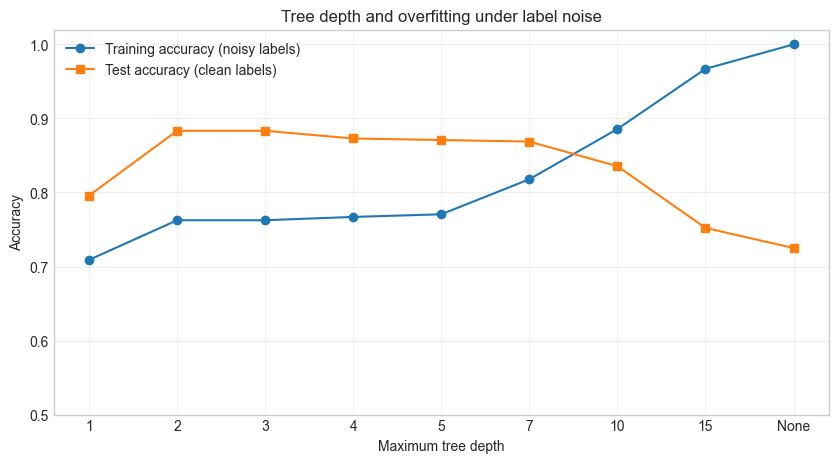

In [16]:
positions = np.arange(len(overfit_results))
plt.figure(figsize=(10, 5))
plt.plot(
    positions, overfit_results["train_acc_noisy"],
    marker="o", label="Training accuracy (noisy labels)"
)
plt.plot(
    positions, overfit_results["test_acc_clean"],
    marker="s", label="Test accuracy (clean labels)"
)
plt.xticks(positions, overfit_results["max_depth"].astype(str))
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.02)
plt.title("Tree depth and overfitting under label noise")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Interpretation

A shallow tree may underfit because it cannot represent the nonlinear boundary. As depth increases, the model becomes more flexible and can fit more of the noisy training labels. At large depths, training accuracy can continue to improve even when test accuracy stops improving or deteriorates. This is the characteristic pattern of overfitting.

**Observed in this run.** 18.0% of the training labels were flipped. The training accuracy (measured against the *noisy* labels) rises from 0.709 at depth 1 to 1.000 for the unrestricted tree (27 levels, 313 leaves), which has memorized the noise. The test accuracy on clean labels is highest at `max_depth=2` (0.883) and is 0.725 for the unrestricted tree, a drop of 0.158. The gap between the two curves is the overfitting.

The exact values depend on the data split, the random seeds and the library version.

# Presenter B: Pruning Decision Trees

The previous experiments demonstrated that unrestricted decision trees can overfit training data, especially when the data contains noise.

Pruning is a technique used to control the complexity of a decision tree by removing unnecessary branches.

In this section, we study pre-pruning and post-pruning, cost-complexity pruning, weakest-link pruning, and the selection of the pruning parameter using cross-validation.

We also investigate the effect of pruning on generalization performance and the bias-variance trade-off.

## 1. Pre-pruning vs Post-pruning

There are two main approaches to controlling the complexity of decision trees.

**Pre-pruning (Early Stopping)**

Pre-pruning stops the growth of a decision tree before it becomes excessively complex.

Common parameters include:

- `max_depth`: Maximum allowed depth of the tree.
- `min_samples_split`: Minimum number of samples required to split an internal node.
- `min_samples_leaf`: Minimum number of samples required in a leaf.
- `min_impurity_decrease`: Minimum impurity reduction required to perform a split.

**Post-pruning**

Post-pruning first allows a tree to grow and then removes branches that do not provide sufficient improvement.

Unlike pre-pruning, it evaluates the structure of an already-grown tree.

**Key difference:**

Pre-pruning prevents potentially unnecessary splits before they occur, whereas post-pruning evaluates existing branches and removes those that are not sufficiently useful.

Post-pruning can avoid some limitations of early stopping, although it does not guarantee better test performance.

## 2. Cost-Complexity Pruning

Cost-complexity pruning balances the predictive performance of a tree against its structural complexity.

The objective is:

$$
R_\alpha(T) = R(T) + \alpha |\widetilde{T}|
$$

Where:

- $T$: The decision tree.
- $R(T)$: The total classification cost of the terminal nodes.
- $|\widetilde{T}|$: Number of terminal nodes (leaves).
- $\alpha$: Complexity penalty parameter.

The parameter $\alpha$ controls the trade-off between model fit and tree size.

**Effect of alpha:**

- $\alpha = 0$: No additional complexity penalty.
- Small $\alpha$: Limited pruning.
- Large $\alpha$: More aggressive pruning.
- Very large $\alpha$: The tree may collapse to a single root node.

As alpha increases, the resulting tree becomes smaller and simpler.

### Weakest-Link Pruning

Weakest-link pruning is a bottom-up pruning procedure.

At each step, the algorithm identifies the internal node whose removal produces the smallest increase in prediction cost relative to the reduction in tree complexity.

For an internal node $t$, the effective pruning parameter is:

$$
\alpha_t =
\frac{R(t)-R(T_t)}
{|\widetilde{T_t}|-1}
$$

Where:

- $R(t)$: Cost of replacing the entire subtree rooted at $t$ with a single leaf.
- $R(T_t)$: Cost of keeping the original subtree.
- $|\widetilde{T_t}|$: Number of leaves in that subtree.

The weakest link is the subtree with the smallest effective alpha.

The algorithm progressively removes these weakest links, producing a sequence of increasingly simpler trees.

This sequence provides the candidate pruning levels used in cost-complexity pruning.

## 3. Numerical Experiment: Cost-Complexity Pruning on Iris

We use the Iris dataset to investigate the effect of cost-complexity pruning.

The original decision tree was trained in the previous section using a stratified 70/30 train-test split.

We first extract the cost-complexity pruning path to obtain the candidate values of `ccp_alpha`.

Each alpha value corresponds to a possible level of tree complexity.

In [17]:
# Extract the cost-complexity pruning path

pruning_path = iris_tree.cost_complexity_pruning_path(
    X_iris_train,
    y_iris_train
)

ccp_alphas = pruning_path.ccp_alphas
impurities = pruning_path.impurities

print("Number of candidate alpha values:", len(ccp_alphas))
print("First alpha:", ccp_alphas[0])
print("Last alpha:", ccp_alphas[-1])

Number of candidate alpha values: 5
First alpha: 0.0
Last alpha: 0.33333333333333354


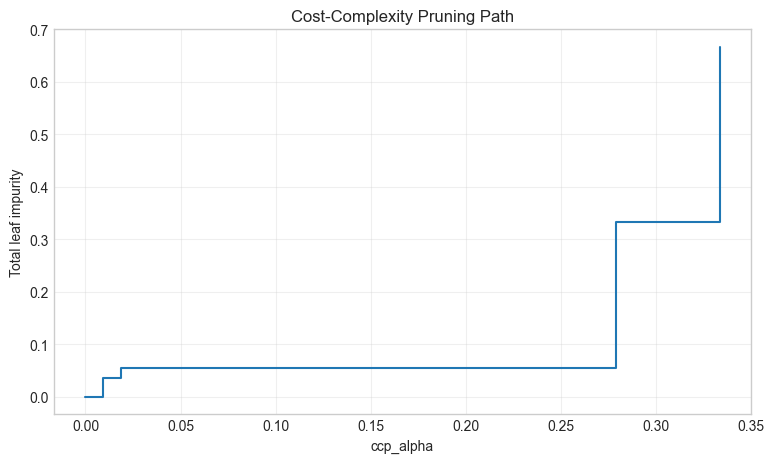

In [18]:
# Visualize the cost-complexity pruning path

plt.figure(figsize=(9, 5))

plt.step(
    ccp_alphas,
    impurities,
    where="post"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Total leaf impurity")
plt.title("Cost-Complexity Pruning Path")

plt.grid(alpha=0.3)
plt.show()

## 4. Selecting the Optimal Alpha Using Cross-Validation

The pruning parameter `ccp_alpha` is a hyperparameter that must be selected carefully.

If alpha is too small, the tree may remain unnecessarily complex.

If alpha is too large, important decision rules may be removed.

We use 5-fold stratified cross-validation to select an appropriate value.

The training dataset is divided into five folds. In each iteration, four folds are used for training and the remaining fold is used for validation.

The process is repeated five times, and the mean validation accuracy is calculated.

The alpha with the highest mean cross-validation accuracy is selected.

**Important:** The test set is not used during hyperparameter selection. It is reserved for the final evaluation.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mean_scores = []
cv_std_scores = []

for alpha in ccp_alphas:

    model = DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=float(alpha)
    )

    scores = cross_val_score(
        model,
        X_iris_train,
        y_iris_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_mean_scores.append(scores.mean())
    cv_std_scores.append(scores.std())

cv_mean_scores = np.array(cv_mean_scores)
cv_std_scores = np.array(cv_std_scores)

best_idx = np.argmax(cv_mean_scores)
best_alpha = float(ccp_alphas[best_idx])

print("Selected alpha:", best_alpha)
print("Mean CV accuracy:", cv_mean_scores[best_idx])
print("CV standard deviation:", cv_std_scores[best_idx])

Selected alpha: 0.01848739495798319
Mean CV accuracy: 0.9428571428571428
CV standard deviation: 0.03563483225498991


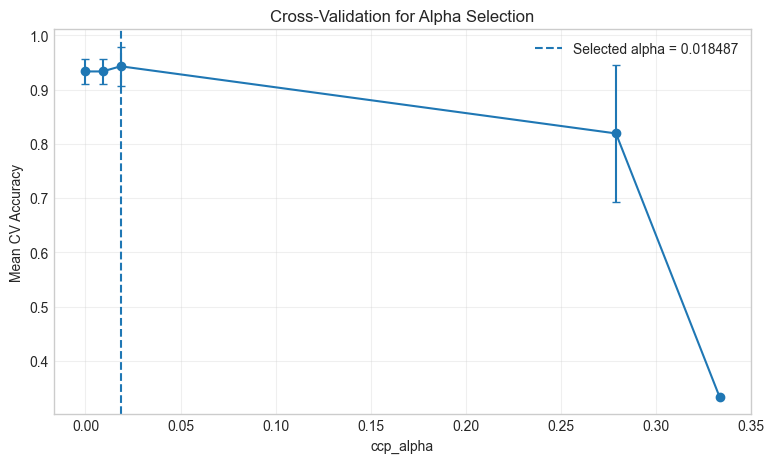

In [20]:
# Plot cross-validation accuracy for different alpha values

plt.figure(figsize=(9, 5))

plt.errorbar(
    ccp_alphas,
    cv_mean_scores,
    yerr=cv_std_scores,
    marker="o",
    capsize=3
)

plt.axvline(
    best_alpha,
    linestyle="--",
    label=f"Selected alpha = {best_alpha:.5g}"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Mean CV Accuracy")
plt.title("Cross-Validation for Alpha Selection")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Comparing Pruned and Unpruned Decision Trees

After selecting the optimal alpha using cross-validation, we train a new decision tree with the selected pruning parameter.

We compare it with the original unrestricted tree.

The evaluation includes:

- Training accuracy.
- Test accuracy.
- Test classification error.
- Tree depth.
- Number of leaves.
- Total number of nodes.

This comparison helps us understand how pruning changes both model complexity and predictive performance.

In [21]:
# Train the pruned decision tree

pruned_iris_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_iris_tree.fit(
    X_iris_train,
    y_iris_train
)

models = {
    "Unpruned Tree": iris_tree,
    "Pruned Tree": pruned_iris_tree
}

results = []

for name, model in models.items():

    train_accuracy = accuracy_score(
        y_iris_train,
        model.predict(X_iris_train)
    )

    test_accuracy = accuracy_score(
        y_iris_test,
        model.predict(X_iris_test)
    )

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Test Error": 1 - test_accuracy,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Total Nodes": model.tree_.node_count
    })

pruning_results = pd.DataFrame(results)

display(pruning_results.round(4))

,Model,Train Accuracy,Test Accuracy,Test Error,Depth,Leaves,Total Nodes
0,Unpruned Tree,1.0000,0.9333,0.0667,5,8,15
1,Pruned Tree,0.9714,0.8889,0.1111,2,3,5


## 6. Test Error vs. ccp_alpha

We now investigate how the test classification error changes as the pruning strength increases.

For every candidate alpha, a new decision tree is trained on the training set and evaluated on the same independent test set.

The resulting curve illustrates the relationship between pruning strength and generalization performance.

The alpha selected through cross-validation is also marked on the plot.

The test error is used only for final evaluation and interpretation, not for selecting alpha.

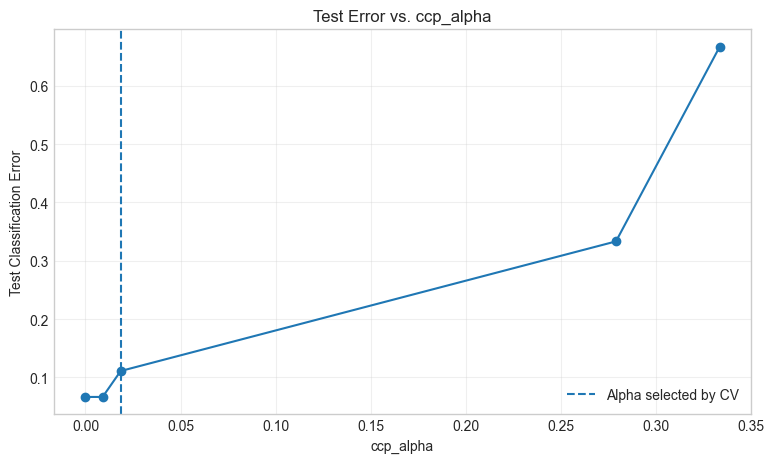

In [22]:
# Evaluate test error for different alpha values

test_errors = []
leaf_counts = []

for alpha in ccp_alphas:

    model = DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=float(alpha)
    )

    model.fit(
        X_iris_train,
        y_iris_train
    )

    predictions = model.predict(X_iris_test)

    test_error = 1 - accuracy_score(
        y_iris_test,
        predictions
    )

    test_errors.append(test_error)
    leaf_counts.append(model.get_n_leaves())


plt.figure(figsize=(9, 5))

plt.plot(
    ccp_alphas,
    test_errors,
    marker="o"
)

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Alpha selected by CV"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Test Classification Error")
plt.title("Test Error vs. ccp_alpha")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Visualizing the Effect of Pruning

To understand the structural effect of pruning, we visualize the original and pruned decision trees.

The comparison allows us to observe:

- Changes in tree depth.
- Reduction in the number of leaves.
- Removal of unnecessary decision branches.
- Simplification of the final decision structure.

We also identify the split rules that were removed during pruning.

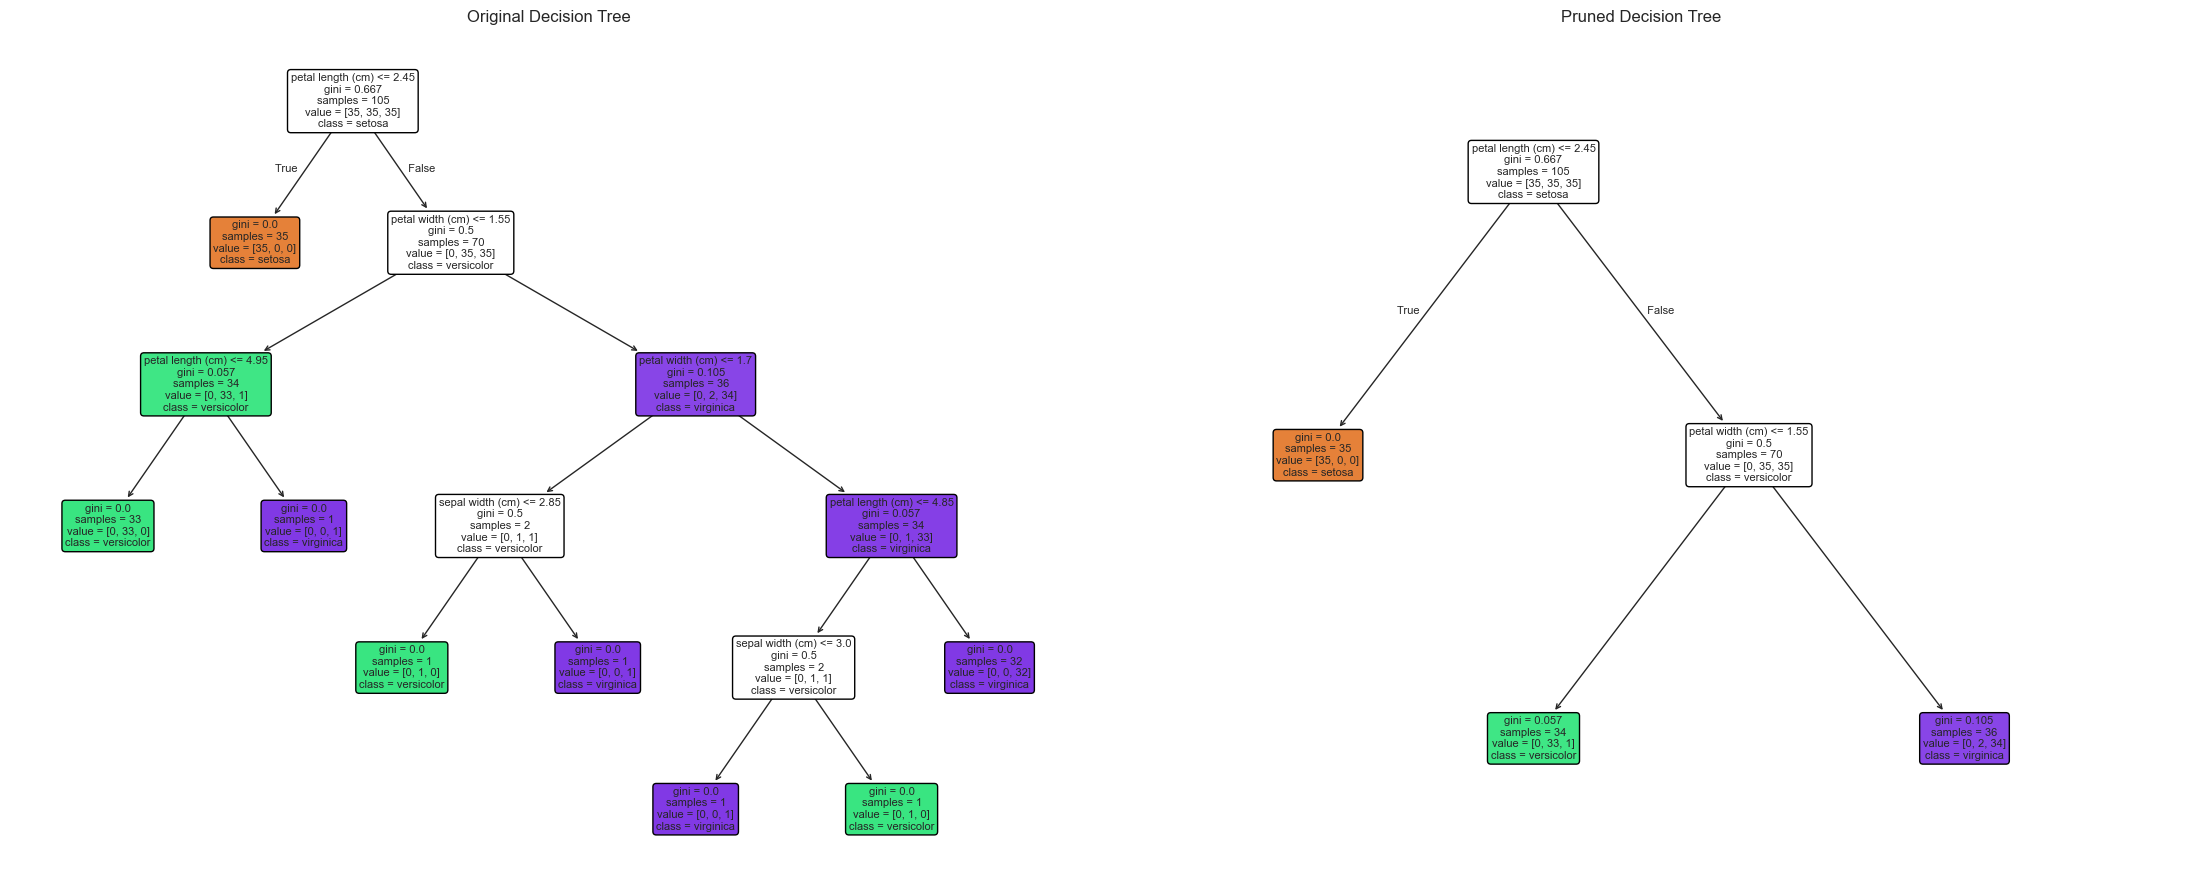

In [23]:
# Compare original and pruned trees

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

plot_tree(
    iris_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=8,
    ax=axes[0]
)

axes[0].set_title("Original Decision Tree")

plot_tree(
    pruned_iris_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=8,
    ax=axes[1]
)

axes[1].set_title("Pruned Decision Tree")

plt.tight_layout()
plt.show()

In [24]:
# Identify the removed decision rules

def get_split_rules(model):

    tree = model.tree_
    rules = []

    for node in range(tree.node_count):

        if tree.children_left[node] != tree.children_right[node]:

            feature = iris.feature_names[tree.feature[node]]

            threshold = round(
                float(tree.threshold[node]), 5
            )

            rules.append((feature, threshold))

    return set(rules)


original_rules = get_split_rules(iris_tree)
pruned_rules = get_split_rules(pruned_iris_tree)

removed_rules = original_rules - pruned_rules

print("Original tree:")
print("Depth:", iris_tree.get_depth())
print("Leaves:", iris_tree.get_n_leaves())

print("\nPruned tree:")
print("Depth:", pruned_iris_tree.get_depth())
print("Leaves:", pruned_iris_tree.get_n_leaves())

print("\nRemoved split rules:")

for rule in sorted(removed_rules):
    print(rule)

Original tree:
Depth: 5
Leaves: 8

Pruned tree:
Depth: 2
Leaves: 3

Removed split rules:
('petal length (cm)', 4.85)
('petal length (cm)', 4.95)
('petal width (cm)', 1.7)
('sepal width (cm)', 2.85)
('sepal width (cm)', 3.0)


## 8. Pruning and the Bias-Variance Trade-off

Pruning directly affects the bias-variance trade-off introduced in Seminar 1.

An unrestricted decision tree may have:

- Low training error.
- Low bias.
- High variance.
- A tendency to overfit noisy observations.

A heavily pruned tree may have:

- Higher bias.
- Lower variance.
- A tendency to underfit the data.

The objective is to find a suitable balance between bias and variance.

Cross-validation provides a practical way to select the pruning strength and control model complexity.

Therefore, pruning is closely connected to the generalization problem discussed in Seminar 1.

## 9. When Does Pruning Fail?

Although pruning can improve generalization, it is not guaranteed to improve every decision tree.

Important failure cases include:

**1. Excessive pruning**

A large alpha may remove important decision rules and lead to underfitting.

**2. Insufficient pruning**

A very small alpha may leave unnecessary branches and preserve overfitting.

**3. Small training datasets**

Cross-validation estimates may become unstable when only a limited number of observations are available.

**4. Unstable decision boundaries**

Small changes in the training data can produce different tree structures.

**5. Complex feature relationships**

Axis-aligned decision trees may require many branches to represent complicated decision boundaries.

Pruning controls complexity, but it cannot solve every limitation of decision trees.

## 10. Connection to Ensemble Learning — Seminar 3

Decision trees are important base learners in ensemble methods.

Their flexibility and controllable complexity make them suitable for combining multiple models.

Examples include:

- Bagging.
- Random Forests.
- Boosting.

A single decision tree may have high variance.

Ensemble methods combine multiple trees to improve prediction stability and generalization.

Random Forests use randomized decision trees and aggregate their predictions to reduce variance.

This provides a natural connection between decision tree pruning and the ensemble methods discussed in Seminar 3.

## References

1. Hastie, T., Tibshirani, R., & Friedman, J. (2009).
   The Elements of Statistical Learning, 2nd Edition.
   Chapter 9, Section 9.2, especially Sections 9.2.1–9.2.4.

2. Duda, R. O., Hart, P. E., & Stork, D. G. (2001).
   Pattern Classification, 2nd Edition.
   Section on Decision Trees.

3. Scikit-learn Documentation:
   - DecisionTreeClassifier
   - Cost Complexity Pruning Path
   - Post-pruning Decision Trees with Cost Complexity Pruning.

Just as using information from two trees improves our results, we might expect that using information from many trees would improve our results even further.

## Ensembles of Estimators: Random Forests

This notion—that multiple overfitting estimators can be combined to reduce the effect of this overfitting—is what underlies an ensemble method called *bagging*.
Bagging makes use of an ensemble (a grab bag, perhaps) of parallel estimators, each of which overfits the data, and averages the results to find a better classification.
An ensemble of randomized decision trees is known as a *random forest*.

This type of bagging classification can be done manually using Scikit-Learn's `BaggingClassifier` meta-estimator, as shown here (see the following figure):

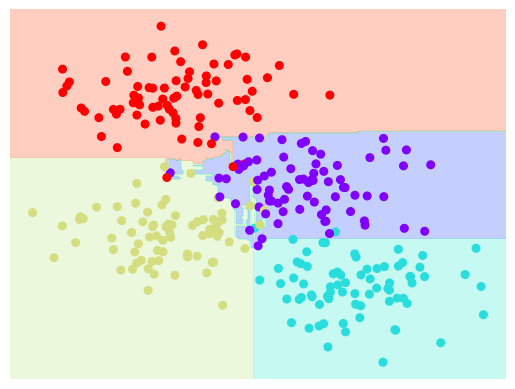

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

tree = DecisionTreeClassifier()
bag = BaggingClassifier(tree, n_estimators=100, max_samples=0.8,
                        random_state=1)

bag.fit(X, y)
visualize_classifier(bag, X, y)

In this example, we have randomized the data by fitting each estimator with a random subset of 80% of the training points.
In practice, decision trees are more effectively randomized by injecting some stochasticity in how the splits are chosen: this way all the data contributes to the fit each time, but the results of the fit still have the desired randomness.
For example, when determining which feature to split on, the randomized tree might select from among the top several features.
You can read more technical details about these randomization strategies in the [Scikit-Learn documentation](http://scikit-learn.org/stable/modules/ensemble.html#forest) and references within.

In Scikit-Learn, such an optimized ensemble of randomized decision trees is implemented in the `RandomForestClassifier` estimator, which takes care of all the randomization automatically.
All you need to do is select a number of estimators, and it will very quickly—in parallel, if desired—fit the ensemble of trees (see the following figure):

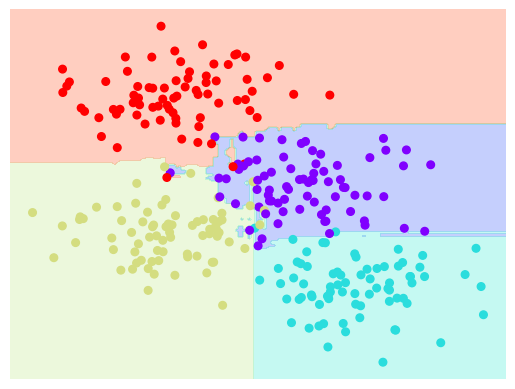

In [26]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=0)
visualize_classifier(model, X, y);

We see that by averaging over 100 randomly perturbed models, we end up with an overall model that is much closer to our intuition about how the parameter space should be split.

## Random Forest Regression

In the previous section we considered random forests within the context of classification.
Random forests can also be made to work in the case of regression (that is, with continuous rather than categorical variables). The estimator to use for this is the `RandomForestRegressor`, and the syntax is very similar to what we saw earlier.

Consider the following data, drawn from the combination of a fast and slow oscillation (see the following figure):

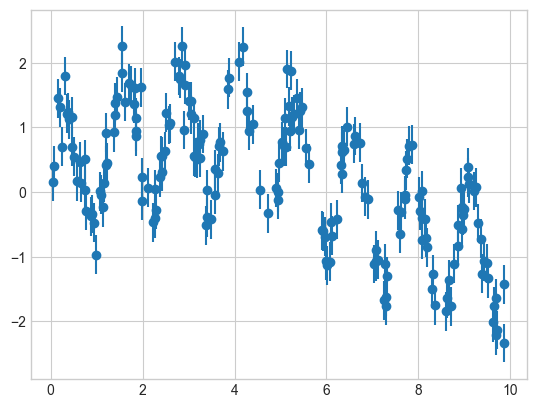

In [27]:
rng = np.random.RandomState(42)
x = 10 * rng.rand(200)

def model(x, sigma=0.3):
    fast_oscillation = np.sin(5 * x)
    slow_oscillation = np.sin(0.5 * x)
    noise = sigma * rng.randn(len(x))

    return slow_oscillation + fast_oscillation + noise

y = model(x)
plt.errorbar(x, y, 0.3, fmt='o');

Using the random forest regressor, we can find the best-fit curve as follows (see the following figure):

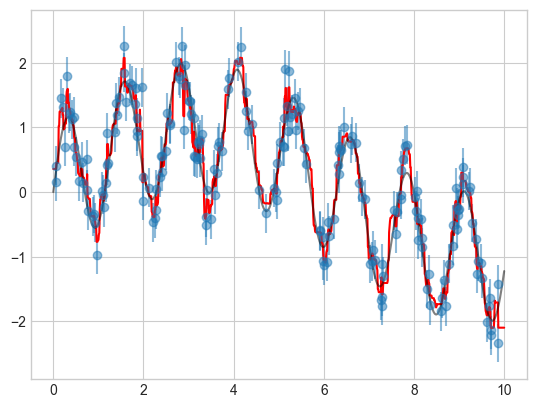

In [28]:
from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor(200)
forest.fit(x[:, None], y)

xfit = np.linspace(0, 10, 1000)
yfit = forest.predict(xfit[:, None])
ytrue = model(xfit, sigma=0)

plt.errorbar(x, y, 0.3, fmt='o', alpha=0.5)
plt.plot(xfit, yfit, '-r');
plt.plot(xfit, ytrue, '-k', alpha=0.5);

Here the true model is shown in the smooth gray curve, while the random forest model is shown by the jagged red curve.
The nonparametric random forest model is flexible enough to fit the multiperiod data, without us needing to specifying a multi-period model!

## Example: Random Forest for Classifying Digits

In Chapter 38 we worked through an example using the digits dataset included with Scikit-Learn.
Let's use that again here to see how the random forest classifier can be applied in this context:

In [29]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

To remind us what we're looking at, we'll visualize the first few data points (see the following figure):

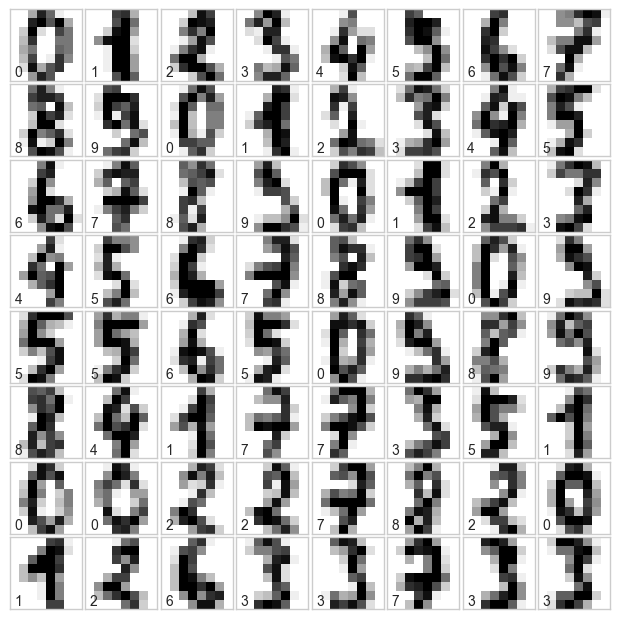

In [30]:
# set up the figure
fig = plt.figure(figsize=(6, 6))  # figure size in inches
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)

# plot the digits: each image is 8x8 pixels
for i in range(64):
    ax = fig.add_subplot(8, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(digits.images[i], cmap=plt.cm.binary, interpolation='nearest')
    
    # label the image with the target value
    ax.text(0, 7, str(digits.target[i]))

We can classify the digits using a random forest as follows:

In [31]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(digits.data, digits.target,
                                                random_state=0)
model = RandomForestClassifier(n_estimators=1000)
model.fit(Xtrain, ytrain)
ypred = model.predict(Xtest)

Let's look at the classification report for this classifier:

In [32]:
from sklearn import metrics
print(metrics.classification_report(ytest, ypred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        37
           1       0.95      0.98      0.97        43
           2       1.00      0.95      0.98        44
           3       0.98      0.98      0.98        45
           4       1.00      0.97      0.99        38
           5       0.96      0.98      0.97        48
           6       1.00      1.00      1.00        52
           7       0.96      1.00      0.98        48
           8       0.98      0.94      0.96        48
           9       0.98      0.98      0.98        47

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450



And for good measure, plot the confusion matrix (see the following figure):

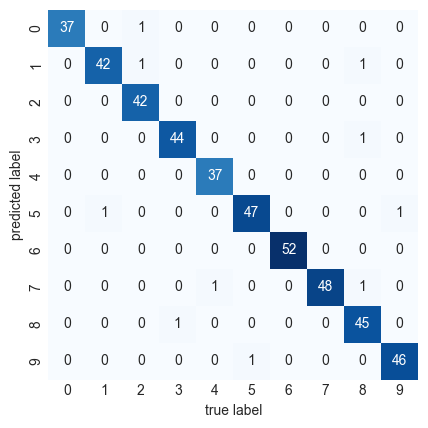

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
mat = confusion_matrix(ytest, ypred)
sns.heatmap(mat.T, square=True, annot=True, fmt='d',
            cbar=False, cmap='Blues')
plt.xlabel('true label')
plt.ylabel('predicted label');

We find that a simple, untuned random forest results in a quite accurate classification of the digits data.

## Summary

This chapter provided a brief introduction to the concept of ensemble estimators, and in particular the random forest, an ensemble of randomized decision trees.
Random forests are a powerful method with several advantages:

- Both training and prediction are very fast, because of the simplicity of the underlying decision trees. In addition, both tasks can be straightforwardly parallelized, because the individual trees are entirely independent entities.
- The multiple trees allow for a probabilistic classification: a majority vote among estimators gives an estimate of the probability (accessed in Scikit-Learn with the `predict_proba` method).
- The nonparametric model is extremely flexible and can thus perform well on tasks that are underfit by other estimators.

A primary disadvantage of random forests is that the results are not easily interpretable: that is, if you would like to draw conclusions about the *meaning* of the classification model, random forests may not be the best choice.